In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Embedding, Dense, LayerNormalization, MultiHeadAttention, Dropout, Add, GlobalAveragePooling1D)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

from sklearn.utils.class_weight import compute_class_weight



In [2]:
# Reading the dataset from the saved CSV file
#path = '/content/drive/MyDrive/Colab Notebooks/Recommendation Engine Dataset/Expanded_User_Purchase_History_Dataset.csv'
path = '/content/drive/MyDrive/Colab Notebooks/Recommendation Engine Dataset/User_Purchase_History_With_Specific_Items.csv'
dataset_with_specific_items = pd.read_csv(path)

# Display the loaded dataset
print(dataset_with_specific_items)

    UserID  Purchase_1  Purchase_2 Purchase_3  Purchase_4  Purchase_5  \
0        1      snacks  milkpowder       nuts         oil         oil   
1        2        meat      juices     spices      juices        nuts   
2        3      spices  chocolates     fruits      snacks  chocolates   
3        4  vegetables        soda       nuts      snacks  vegetables   
4        5  chocolates         oil     spices       bread  milkpowder   
..     ...         ...         ...        ...         ...         ...   
95      96        rice      fruits        oil        nuts        rice   
96      97      fruits         oil     juices      juices      fruits   
97      98        fish        fish       rice  milkpowder         oil   
98      99        soda  chocolates   icecream  chocolates      grains   
99     100  vegetables        soda       fish        nuts       bread   

    Purchase_6  Purchase_7  Purchase_8  Purchase_9  ... Purchase_491  \
0     icecream      fruits  chocolates       bread 

## Method 01

Epoch 1/10
1220/1220 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - loss: 8.5013 - output_1_accuracy: 0.0654 - output_1_loss: 2.8353 - output_2_accuracy: 0.0592 - output_2_loss: 2.8347 - output_3_accuracy: 0.0626 - output_3_loss: 2.8313 - val_loss: 8.3467 - val_output_1_accuracy: 0.0569 - val_output_1_loss: 2.7866 - val_output_2_accuracy: 0.0666 - val_output_2_loss: 2.7808 - val_output_3_accuracy: 0.0677 - val_output_3_loss: 2.7793
Epoch 2/10
1220/1220 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 8.3466 - output_1_accuracy: 0.0640 - output_1_loss: 2.7827 - output_2_accuracy: 0.0644 - output_2_loss: 2.7816 - output_3_accuracy: 0.0622 - output_3_loss: 2.7823 - val_loss: 8.3355 - val_output_1_accuracy: 0.0586 - val_output_1_loss: 2.7803 - val_output_2_accuracy: 0.0613 - val_output_2_loss: 2.7786 - val_output_3_accuracy: 0.0655 - val_output_3_loss: 2.7766
Epoch 3/10
1220/1220 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - loss: 8.3352 - output_1_accuracy: 0.0654 - output_1_loss: 2.7790 - output_2_accuracy: 0.0629 -

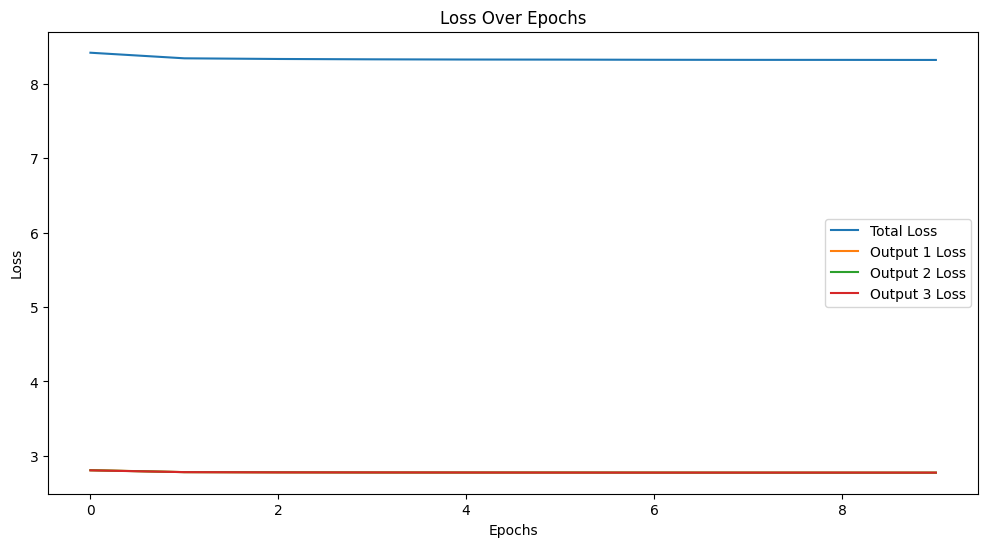

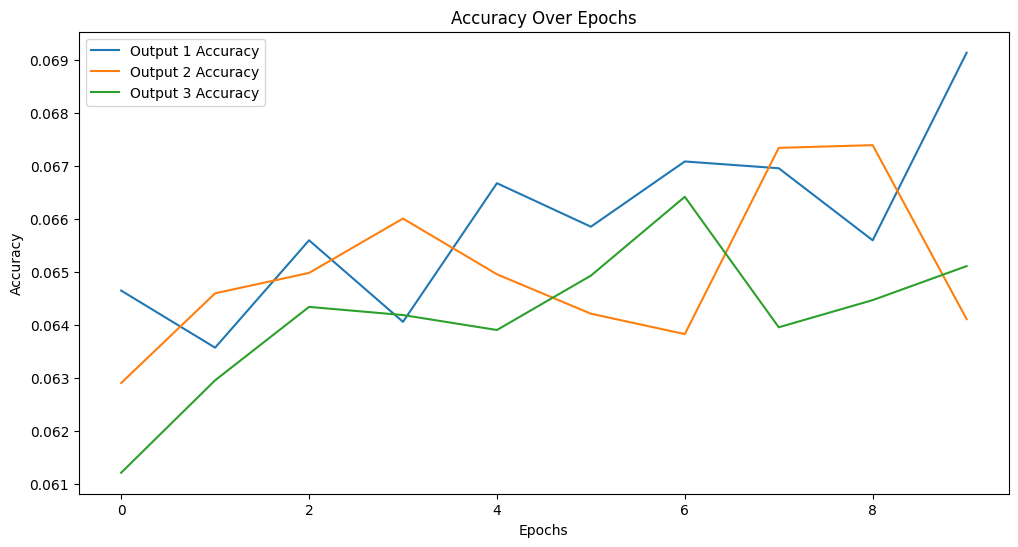

305/305 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 8.3285 - output_1_accuracy: 0.0611 - output_1_loss: 2.7799 - output_2_accuracy: 0.0683 - output_2_loss: 2.7732 - output_3_accuracy: 0.0595 - output_3_loss: 2.7754
Test Loss for Output 1: 2.7794346809387207
Test Loss for Output 2: 2.7746806144714355
Test Loss for Output 3: 2.7746291160583496
Total Test Loss: 8.328743934631348


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, MultiHeadAttention, Dense, LayerNormalization, Dropout, GlobalAveragePooling1D
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

# Load the dataset
path = '/content/drive/MyDrive/Colab Notebooks/Recommendation Engine Dataset/User_Purchase_History_With_Specific_Items.csv'
user_data = pd.read_csv(path)

# Preprocessing
tokenizer = Tokenizer()
user_data_flat = user_data.iloc[:, 1:].values.flatten()  # Flatten all purchase columns
tokenizer.fit_on_texts(user_data_flat)

# Convert items to numerical sequences for each user
item_sequences = user_data.iloc[:, 1:].apply(lambda row: tokenizer.texts_to_sequences(row), axis=1)
item_sequences = item_sequences.apply(lambda seqs: [item[0] for item in seqs])

# Pad sequences and prepare input-output pairs for training
max_sequence_length = 10  # Use the last 10 items to predict the next 3
inputs, targets = [], []

for seq in item_sequences:
    if len(seq) > max_sequence_length + 3:
        for i in range(len(seq) - max_sequence_length - 3 + 1):
            inputs.append(seq[i : i + max_sequence_length])
            targets.append(seq[i + max_sequence_length : i + max_sequence_length + 3])

# inputs = pad_sequences(inputs, maxlen=max_sequence_length, padding='post')
# targets = pad_sequences(targets, maxlen=3, padding='post')

# # Split data into training and testing sets
# X_train, X_test, y_train, y_test = train_test_split(inputs, targets, test_size=0.2, random_state=42)

# # Flatten targets to match model output
# y_train = y_train.reshape(-1)
# y_test = y_test.reshape(-1)

# # Convert targets into 2D arrays (num_samples, 3)
# y_train = pad_sequences(targets, maxlen=3, padding='post')
# y_test = pad_sequences(targets, maxlen=3, padding='post')

# # Explicit reshaping for safety
# y_train = y_train.reshape(-1, 3)
# y_test = y_test.reshape(-1, 3)

# # Separate targets for model training
# y_train_1, y_train_2, y_train_3 = y_train[:, 0], y_train[:, 1], y_train[:, 2]
# y_test_1, y_test_2, y_test_3 = y_test[:, 0], y_test[:, 1], y_test[:, 2]

# Recreate inputs and targets ensuring consistent cardinality
inputs, targets = [], []

# Adjust for sequence length and next-3 prediction
for seq in item_sequences:
    if len(seq) > max_sequence_length + 3:
        for i in range(len(seq) - max_sequence_length - 3 + 1):
            inputs.append(seq[i : i + max_sequence_length])
            targets.append(seq[i + max_sequence_length : i + max_sequence_length + 3])

# Convert lists to arrays
inputs = pad_sequences(inputs, maxlen=max_sequence_length, padding='post')
targets = pad_sequences(targets, maxlen=3, padding='post')

# Check that inputs and targets have the same number of samples
assert len(inputs) == len(targets), "Mismatch in the number of input and target samples."

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(inputs, targets, test_size=0.2, random_state=42)

# Reshape targets for model outputs
y_train_1, y_train_2, y_train_3 = y_train[:, 0], y_train[:, 1], y_train[:, 2]
y_test_1, y_test_2, y_test_3 = y_test[:, 0], y_test[:, 1], y_test[:, 2]

# Ensure consistent cardinality
assert X_train.shape[0] == y_train_1.shape[0] == y_train_2.shape[0] == y_train_3.shape[0], "Mismatch in training data sizes."
assert X_test.shape[0] == y_test_1.shape[0] == y_test_2.shape[0] == y_test_3.shape[0], "Mismatch in testing data sizes."


# Transformer model definition
def transformer_model(vocab_size, max_len):
    input_layer = Input(shape=(max_len,))
    embedding_layer = Embedding(input_dim=vocab_size, output_dim=64)(input_layer)

    # Multi-head attention block
    attention_output = MultiHeadAttention(num_heads=4, key_dim=64)(embedding_layer, embedding_layer)
    attention_output = LayerNormalization()(attention_output + embedding_layer)

    # Feed-forward network
    dense_output = Dense(128, activation='relu')(attention_output)
    dense_output = Dropout(0.3)(dense_output)
    dense_output = Dense(64, activation='relu')(dense_output)
    dense_output = LayerNormalization()(dense_output + attention_output)

    # Separate output layers for each of the 3 predictions
    output_1 = Dense(vocab_size, activation='softmax', name="output_1")(GlobalAveragePooling1D()(dense_output))
    output_2 = Dense(vocab_size, activation='softmax', name="output_2")(GlobalAveragePooling1D()(dense_output))
    output_3 = Dense(vocab_size, activation='softmax', name="output_3")(GlobalAveragePooling1D()(dense_output))

    return Model(inputs=input_layer, outputs=[output_1, output_2, output_3])


# Hyperparameters
vocab_size = len(tokenizer.word_index) + 1
model = transformer_model(vocab_size, max_sequence_length)

# Compile the model with metrics for each output
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics={'output_1': 'accuracy', 'output_2': 'accuracy', 'output_3': 'accuracy'}
)


# Train the model
history = model.fit(
    X_train, [y_train_1, y_train_2, y_train_3],
    validation_data=(X_test, [y_test_1, y_test_2, y_test_3]),
    epochs=10,
    batch_size=32
)


# Plot loss for each output
plt.figure(figsize=(12, 6))
plt.plot(history.history['loss'], label='Total Loss')
plt.plot(history.history['output_1_loss'], label='Output 1 Loss')
plt.plot(history.history['output_2_loss'], label='Output 2 Loss')
plt.plot(history.history['output_3_loss'], label='Output 3 Loss')
plt.title('Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Accuracy for each output
plt.figure(figsize=(12, 6))
plt.plot(history.history['output_1_accuracy'], label='Output 1 Accuracy')
plt.plot(history.history['output_2_accuracy'], label='Output 2 Accuracy')
plt.plot(history.history['output_3_accuracy'], label='Output 3 Accuracy')
plt.title('Accuracy Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


# Save the model
model.save('transformer_recommendation_model.h5')

# Evaluate the model
# Evaluate the model with separate targets for each output
test_loss = model.evaluate(
    X_test,
    [y_test_1, y_test_2, y_test_3]
)

# Output the test loss for each output
print(f"Test Loss for Output 1: {test_loss[1]}")
print(f"Test Loss for Output 2: {test_loss[2]}")
print(f"Test Loss for Output 3: {test_loss[3]}")
print(f"Total Test Loss: {test_loss[0]}")



## Method 02

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Load the dataset
path = '/content/drive/MyDrive/Colab Notebooks/Recommendation Engine Dataset/User_Purchase_History_With_Specific_Items.csv'
data = pd.read_csv(path)

# Map item names to unique IDs
item_mapping = {item: idx for idx, item in enumerate(pd.unique(data.iloc[:, 1:].values.flatten()), start=1)}
item_mapping_reverse = {v: k for k, v in item_mapping.items()}

# Convert dataset to sequences of item IDs
sequences = data.iloc[:, 1:].applymap(lambda x: item_mapping[x]).values.tolist()

# Create input-output pairs
max_sequence_length = 10  # Use last 10 items to predict the next item
inputs, targets = [], []
for seq in sequences:
    for i in range(len(seq) - max_sequence_length):
        inputs.append(seq[i:i + max_sequence_length])
        targets.append(seq[i + max_sequence_length])

# Pad input sequences
X = pad_sequences(inputs, maxlen=max_sequence_length, padding='post')

# Convert targets to array
y = tf.keras.utils.to_categorical(targets, num_classes=len(item_mapping) + 1)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


<ipython-input-3-8802abbe9d0d>:14: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sequences = data.iloc[:, 1:].applymap(lambda x: item_mapping[x]).values.tolist()


In [4]:
def user_encoder(max_sequence_length, embedding_dim, num_heads, ff_dim, dropout_rate):
    input_seq = Input(shape=(max_sequence_length, embedding_dim))

    # Multi-head Attention
    attention_output = MultiHeadAttention(num_heads=num_heads, key_dim=embedding_dim)(input_seq, input_seq)
    attention_output = Dropout(dropout_rate)(attention_output)
    out1 = LayerNormalization(epsilon=1e-6)(Add()([input_seq, attention_output]))

    # Feed-forward network
    ffn_output = Dense(ff_dim, activation='relu')(out1)
    ffn_output = Dense(embedding_dim)(ffn_output)
    ffn_output = Dropout(dropout_rate)(ffn_output)
    out2 = LayerNormalization(epsilon=1e-6)(Add()([out1, ffn_output]))

    return Model(inputs=input_seq, outputs=out2, name="UserEncoder")


In [5]:
def transrec_model(vocab_size, max_sequence_length, embedding_dim, num_heads, ff_dim, dropout_rate):
    # Inputs
    input_seq = Input(shape=(max_sequence_length,))

    # Item Encoder
    item_encoder = Embedding(input_dim=vocab_size, output_dim=embedding_dim, name="ItemEmbedding")
    item_embeddings = item_encoder(input_seq)

    # User Encoder (Transformer)
    user_encoder_layer = user_encoder(max_sequence_length, embedding_dim, num_heads, ff_dim, dropout_rate)
    user_representation = user_encoder_layer(item_embeddings)

    # Output layer (predict next item)
    output = Dense(vocab_size, activation='softmax', name="NextItemPrediction")(user_representation[:, -1, :])

    return Model(inputs=input_seq, outputs=output)


In [6]:
# Define the model
vocab_size = len(item_mapping) + 1  # Including padding
embedding_dim = 128
num_heads = 4
ff_dim = 256
dropout_rate = 0.1

model = transrec_model(vocab_size, max_sequence_length, embedding_dim, num_heads, ff_dim, dropout_rate)

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=20,
    batch_size=32
)


Epoch 1/20
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 82s 63ms/step - accuracy: 0.0609 - loss: 2.9040 - val_accuracy: 0.0640 - val_loss: 2.8210
Epoch 2/20
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 84s 65ms/step - accuracy: 0.0603 - loss: 2.8074 - val_accuracy: 0.0622 - val_loss: 2.7873
Epoch 3/20
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 82s 67ms/step - accuracy: 0.0652 - loss: 2.7891 - val_accuracy: 0.0637 - val_loss: 2.7827
Epoch 4/20
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 73s 60ms/step - accuracy: 0.0656 - loss: 2.7811 - val_accuracy: 0.0639 - val_loss: 2.7757
Epoch 5/20
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 84s 62ms/step - accuracy: 0.0689 - loss: 2.7767 - val_accuracy: 0.0578 - val_loss: 2.7800
Epoch 6/20
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 83s 63ms/step - accuracy: 0.0641 - loss: 2.7765 - val_accuracy: 0.0605 - val_loss: 2.7776
Epoch 7/20
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 82s 63ms/step - accuracy: 0.0644 - loss: 2.7745 - val_accuracy: 0.0599 - val_loss: 2.7765
Epoch 8/20
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 80s 61ms/step - accuracy: 0.0633 -

In [7]:
model.save('Recommendation_Engine_v4.h5')

307/307 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.0606 - loss: 2.7742
Test Loss: 2.7754108905792236
Test Accuracy: 0.0626530647277832


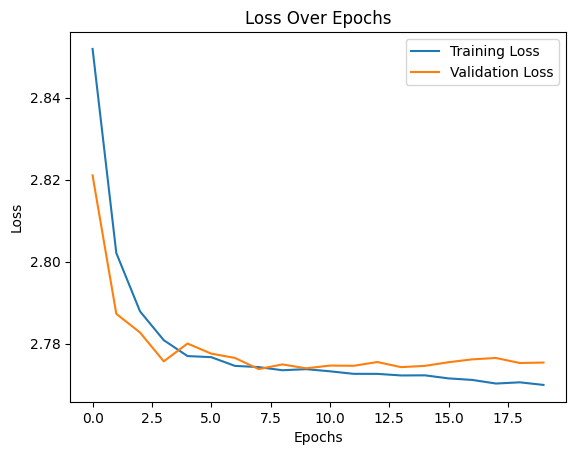

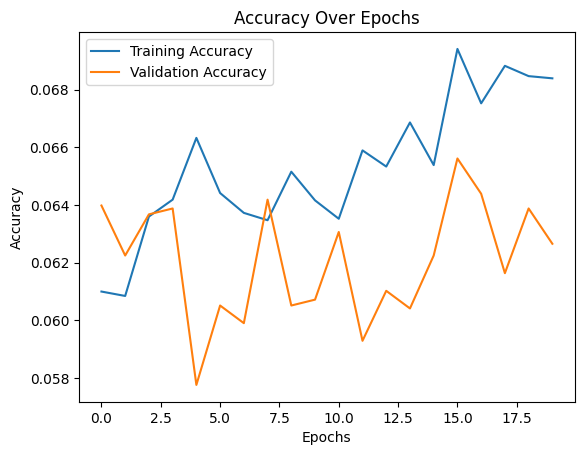

In [8]:
# Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")

# Plot training history
import matplotlib.pyplot as plt

# Loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


In [ ]:
# Map item names to IDs
def generate_recommendations(user_sequence, top_k=3):
    user_sequence = [item_mapping[item] for item in user_sequence]
    user_sequence = pad_sequences([user_sequence], maxlen=max_sequence_length, padding='post')
    predictions = model.predict(user_sequence)[0]
    recommended_items = predictions.argsort()[-top_k:][::-1]
    return [item_mapping_reverse[item] for item in recommended_items]

# Example usage
user_sequence = ['snacks', 'milkpowder', 'nuts', 'oil', 'bread']
print("Recommendations:", generate_recommendations(user_sequence))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Recommendations: ['meat', 'icecream', 'grains']


In [9]:
def generate_user_recommendations(user_id, user_sequence, top_k=3):
    """
    Generate top-k item recommendations for a specific user's purchase history.

    Args:
        user_id (int): ID of the user for whom recommendations are being generated.
        user_sequence (list): List of the user's past purchased items.
        top_k (int): Number of recommendations to generate.

    Returns:
        list: Recommended item names or an error message if an item is invalid.
    """
    # Map user sequence to IDs
    try:
        user_sequence_ids = [item_mapping[item] for item in user_sequence if pd.notnull(item)]
        print(f"Processed input sequence for User {user_id}: {user_sequence_ids}")
    except KeyError as e:
        return f"Item '{e.args[0]}' in User {user_id}'s sequence not found in the item mapping."

    # Pad the sequence
    user_sequence_padded = pad_sequences([user_sequence_ids], maxlen=max_sequence_length, padding='post')
    print(f"Padded sequence for User {user_id}: {user_sequence_padded}")

    # Predict the next item
    predictions = model.predict(user_sequence_padded, verbose=0)[0]  # Shape: (vocab_size,)
    print(f"Predictions for User {user_id}: {predictions[:10]}")  # Show top 10 predictions

    # Get top-k item IDs
    recommended_item_ids = predictions.argsort()[-top_k:][::-1]  # Sort and get top-k in descending order

    # Map IDs back to item names
    recommended_items = [item_mapping_reverse[item_id] for item_id in recommended_item_ids]

    return recommended_items



In [10]:
# Example 1
user_sequence_1 = ['snacks', 'milkpowder', 'nuts', 'oil', 'bread']
recommendations_1 = generate_user_recommendations(1, user_sequence_1, top_k=3)
print(f"Recommendations for sequence 1: {recommendations_1}")

# Example 2
user_sequence_2 = ['vegetables', 'bread', 'fruits', 'oil', 'milkpowder']
recommendations_2 = generate_user_recommendations(2, user_sequence_2, top_k=3)
print(f"Recommendations for sequence 2: {recommendations_2}")


Processed input sequence for User 1: [1, 2, 3, 4, 8]
Padded sequence for User 1: [[1 2 3 4 8 0 0 0 0 0]]
Predictions for User 1: [6.3222892e-06 6.5367810e-02 6.1952412e-02 5.8420267e-02 5.7572193e-02
 6.2782027e-02 6.1204754e-02 6.3210592e-02 6.1514277e-02 5.9186179e-02]
Recommendations for sequence 1: ['vegetables', 'grains', 'snacks']
Processed input sequence for User 2: [12, 8, 6, 4, 2]
Padded sequence for User 2: [[12  8  6  4  2  0  0  0  0  0]]
Predictions for User 2: [4.7073445e-06 6.3084744e-02 6.1522011e-02 5.8160171e-02 5.7203729e-02
 6.5594956e-02 6.2204458e-02 6.3526027e-02 6.2415343e-02 5.8169704e-02]
Recommendations for sequence 2: ['spices', 'grains', 'rice']
